# Linear Discriminant Analysis (LDA)

## Importing the libraries

In [1]:
# numpy       -> array handling (used by the plotting cells)
# matplotlib  -> drawing the decision-boundary charts
# pandas      -> loading the dataset
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from matplotlib.colors import ListedColormap

from typing import Protocol
import numpy.typing as npt
from matplotlib.axes import Axes

## Importing the dataset

In [2]:
# read the wine dataset
dataset = pd.read_csv('data/Wine.csv')

# X = every column except the last (the 13 chemical measurements)
# y = the last column (Customer_Segment - the wine type, 1, 2 or 3)
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

In [3]:
from notebook_display import display_table

preview = pd.DataFrame(X).copy()
preview["Target"] = np.asarray(y).ravel()

display_table(preview.head(10).reset_index(drop=True), fit_to_page=True)

0,1,2,3,4,5,6,7,8,9,10,11,12,Target
14.230000,1.710000,2.430000,15.600000,127.000000,2.800000,3.060000,0.280000,2.290000,5.640000,1.040000,3.920000,1065.000000,1
13.200000,1.780000,2.140000,11.200000,100.000000,2.650000,2.760000,0.260000,1.280000,4.380000,1.050000,3.400000,1050.000000,1
13.160000,2.360000,2.670000,18.600000,101.000000,2.800000,3.240000,0.300000,2.810000,5.680000,1.030000,3.170000,1185.000000,1
14.370000,1.950000,2.500000,16.800000,113.000000,3.850000,3.490000,0.240000,2.180000,7.800000,0.860000,3.450000,1480.000000,1
13.240000,2.590000,2.870000,21.000000,118.000000,2.800000,2.690000,0.390000,1.820000,4.320000,1.040000,2.930000,735.000000,1
14.200000,1.760000,2.450000,15.200000,112.000000,3.270000,3.390000,0.340000,1.970000,6.750000,1.050000,2.850000,1450.000000,1
14.390000,1.870000,2.450000,14.600000,96.000000,2.500000,2.520000,0.300000,1.980000,5.250000,1.020000,3.580000,1290.000000,1
14.060000,2.150000,2.610000,17.600000,121.000000,2.600000,2.510000,0.310000,1.250000,5.050000,1.060000,3.580000,1295.000000,1
14.830000,1.640000,2.170000,14.000000,97.000000,2.800000,2.980000,0.290000,1.980000,5.200000,1.080000,2.850000,1045.000000,1
13.860000,1.350000,2.270000,16.000000,98.000000,2.980000,3.150000,0.220000,1.850000,7.220000,1.010000,3.550000,1045.000000,1


In [4]:
print(y)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3]


## Splitting the dataset into the Training set and Test set

In [5]:
# split into training (80%) and test (20%) sets
# random_state=0 makes the split reproducible - same rows every run
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

## Feature Scaling

In [6]:
# standardise the features: rescale each column to mean 0, standard deviation 1
# fit_transform on TRAIN learns the means and stds; transform on TEST reuses them
# (never fit on the test set - that would leak test information into the model)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

## Applying LDA

In [7]:
# LDA reduces the 13 measurements down to 2 new features (LD1 and LD2)
# note that fit_transform receives y_train as well - LDA is SUPERVISED:
# it uses the wine types to choose the 2 directions that best separate the classes
lda = LDA(n_components = 2)
X_train = lda.fit_transform(X_train, y_train)
X_test = lda.transform(X_test)   # the test set is transformed with the same directions

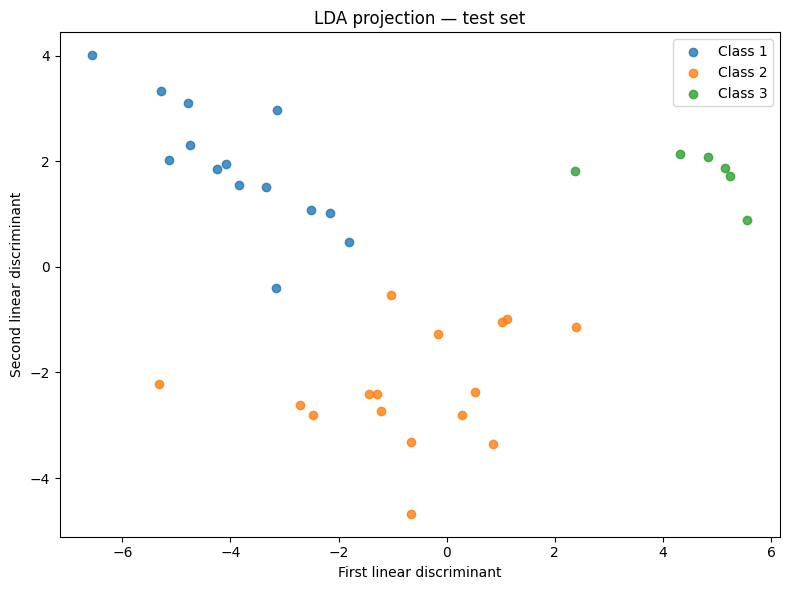

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))

for class_label in np.unique(y_test):
    mask = np.asarray(y_test).ravel() == class_label
    ax.scatter(
        X_test[mask, 0],
        X_test[mask, 1],
        label=f"Class {class_label}",
        alpha=0.8,
    )

ax.set_xlabel("First linear discriminant")
ax.set_ylabel("Second linear discriminant")
ax.set_title("LDA projection — test set")
ax.legend()
fig.tight_layout()
plt.show()

## Training the Logistic Regression model on the Training set

In [9]:
# train Logistic Regression on the 2 LDA features
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

LogisticRegression(random_state=0)

## Making the Confusion Matrix

In [10]:
# predict the wine type for the test set and count the results
# rows = actual type, columns = predicted type
y_pred = classifier.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)
#accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")

[[14  0  0]
 [ 0 16  0]
 [ 0  0  6]]
Test accuracy: 100.00%


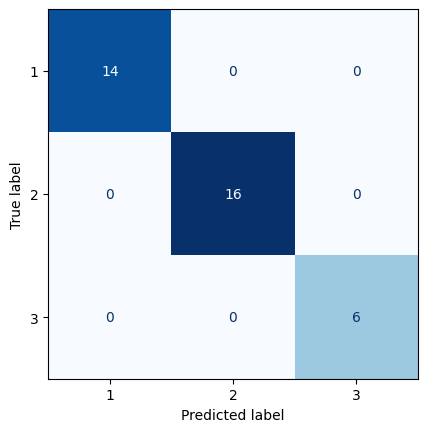

In [11]:
'''cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(confusion_matrix=cm).plot(
    cmap="Blues",
    values_format="d",
    colorbar=False,
)
plt.title("Confusion matrix")
plt.tight_layout()'''

# This alternative uses the label names so the classes are labelled correctly (1 to 3). Otherwise they will be zero to two.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[1, 2, 3],
    cmap="Blues",
    values_format="d",
    colorbar=False,
)
plt.show()

## Visualising the training and test results

In [12]:
class Classifier(Protocol):
    """Interface required by the plotting function."""

    classes_: npt.NDArray

    def predict(self, X: npt.ArrayLike) -> npt.NDArray:
        ...

def plot_decision_regions(
    X_set: npt.ArrayLike,
    y_set: npt.ArrayLike,
    title: str,
    *,
    classifier: Classifier,
    ax: Axes | None = None,
    grid_step: float = 0.01,
) -> Axes:
    """Plot a fitted classifier's decision regions in two LDA dimensions.

    X_set must contain exactly two columns in the coordinate system used
    to fit the classifier. y_set supplies the true labels for those samples.

    Supply ax to draw on an existing subplot. Otherwise, create and display
    a standalone figure. The classifier is used for prediction, not refitted.

    Returns:
        The axes containing the decision regions and labelled samples.
    """
    X = np.asarray(X_set)
    y = np.asarray(y_set).ravel()
    classes = np.asarray(classifier.classes_)

    if X.ndim != 2 or X.shape[1] != 2:
        raise ValueError("X_set must have exactly two columns.")
    if len(X) == 0 or len(X) != len(y):
        raise ValueError("X_set and y_set must have the same nonzero length.")
    if not np.isfinite(grid_step) or grid_step <= 0:
        raise ValueError("grid_step must be a positive, finite number.")
    if not np.isin(y, classes).all():
        raise ValueError("y_set contains labels unknown to the classifier.")

    # Use the fitted model's class order so colours stay consistent
    # across training/test plots, even when a subset lacks a class.
    colours = (
        ["red", "green", "blue"][:len(classes)]
        if len(classes) <= 3
        else plt.get_cmap("tab20", len(classes))(np.arange(len(classes)))
    )
    cmap = ListedColormap(colours)
    class_to_index = {label: i for i, label in enumerate(classes)}

    # Build a fine grid covering the samples, with a margin on each side.
    X1, X2 = np.meshgrid(
        np.arange(X[:, 0].min() - 1, X[:, 0].max() + 1, grid_step),
        np.arange(X[:, 1].min() - 1, X[:, 1].max() + 1, grid_step),
    )
    grid_points = np.column_stack((X1.ravel(), X2.ravel()))

    # Predict each grid point, then map class labels to colour indices.
    # This supports labels such as 1–3 or strings, not just 0–2.
    grid_predictions = classifier.predict(grid_points)
    region_indices = np.array([
        class_to_index[label] for label in grid_predictions
    ]).reshape(X1.shape)

    standalone = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))

    # Explicit boundaries give each class its own discrete colour region.
    ax.contourf(
        X1,
        X2,
        region_indices,
        levels=np.arange(len(classes) + 1) - 0.5,
        cmap=cmap,
        vmin=-0.5,
        vmax=len(classes) - 0.5,
        alpha=0.35,
    )

    # Overlay the actual wines, coloured by their true class.
    for i, label in enumerate(classes):
        mask = y == label
        if mask.any():
            ax.scatter(
                X[mask, 0],
                X[mask, 1],
                color=colours[i],
                edgecolors="black",
                linewidths=0.5,
                label=str(label),
            )

    ax.set(
        title=title,
        xlabel="LD1",
        ylabel="LD2",
        xlim=(X1.min(), X1.max()),
        ylim=(X2.min(), X2.max()),
    )
    ax.legend(title="Actual class")

    if standalone:
        ax.figure.tight_layout()
        plt.show()

    return ax


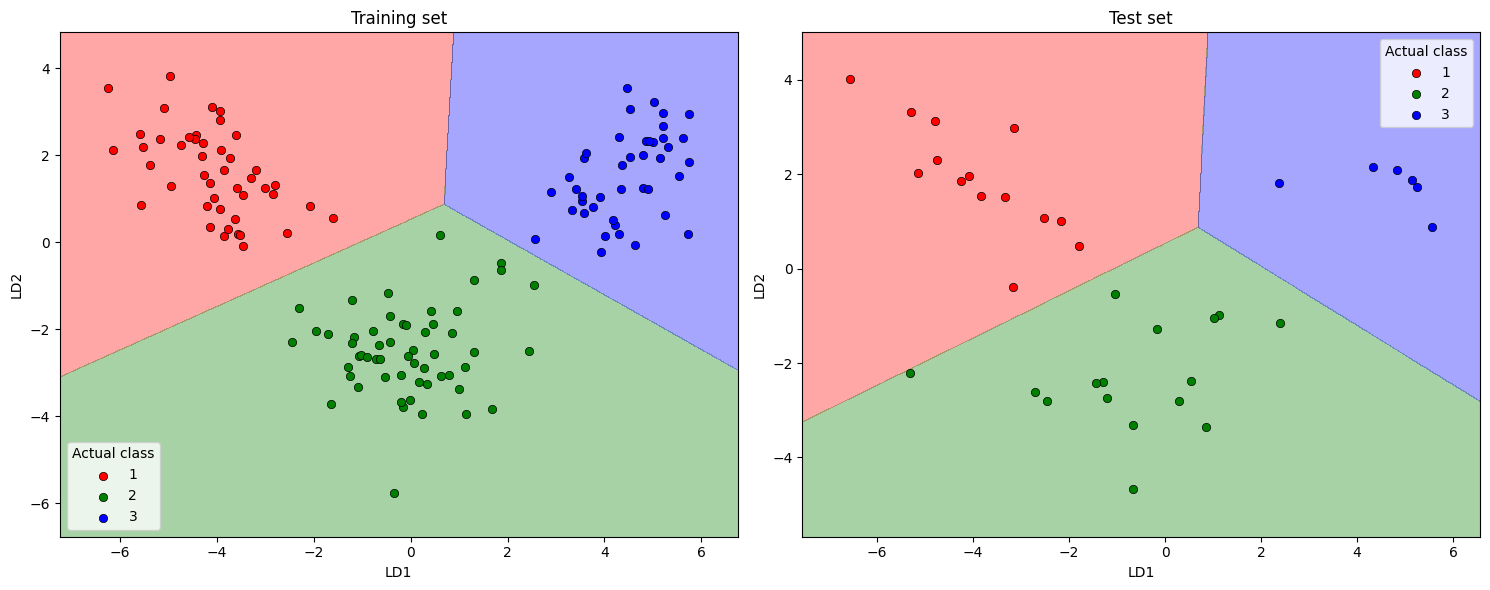

In [13]:
'''
# draw the decision regions: colour every point of the 2-D plane by the
# class the model would predict there, then plot the real wines on top
plot_decision_regions(X_train, y_train, 'Logistic Regression (Training set)', classifier=classifier,)

# same picture as above, but with the TEST wines - data the model never trained on
plot_decision_regions(X_test, y_test, 'Logistic Regression (Test set)', classifier=classifier,)
'''

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plot_decision_regions(
    X_train,
    y_train,
    "Training set",
    classifier=classifier,
    ax=axes[0],
)

plot_decision_regions(
    X_test,
    y_test,
    "Test set",
    classifier=classifier,
    ax=axes[1],
)

fig.tight_layout()
plt.show()


<h1>What did we learn?</h1>

- **LDA is supervised dimensionality reduction.** Unlike PCA in the previous lab,
  LDA is given the class labels and uses them to choose the 2 directions that best
  separate the three wine types.
- **13 measurements became 2 features (LD1 and LD2)** — and because those directions
  were chosen to separate the classes, the three wine types form three clean,
  well-separated groups on the plot.
- **A simple model was enough after LDA.** Logistic Regression on just the 2 LDA
  features classified the test set perfectly — the confusion matrix has every wine
  on the diagonal.
- **The decision-boundary plots show how the model thinks.** The coloured regions
  are the model's prediction for every possible point; the dots are real wines.
  Where a dot sits in its own colour, the model got it right.
- **Same rule as always:** the scaler and LDA were fitted on the training set only,
  then applied to the test set — the test data stayed unseen until marking time.